In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yaml
import sys
from pathlib import Path
import mlflow
import os
import joblib
import logging
import gc

In [68]:
pip install catboost

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2
[notice] To update, run: C:\Users\HP\Documents\Fraud_Detection_System\fraud_detection\Scripts\python.exe -m pip install --upgrade pip


In [69]:
pip show catboost

Name: catboost
Version: 1.2.10
Summary: CatBoost Python Package
Home-page: https://catboost.ai
Author: CatBoost Developers
Author-email: 
License: Apache License, Version 2.0
Location: C:\Users\HP\Documents\Fraud_Detection_System\fraud_detection\Lib\site-packages
Requires: graphviz, matplotlib, numpy, pandas, plotly, scipy, six
Required-by: 
Note: you may need to restart the kernel to use updated packages.


# Loading & Splits

## Loading

### Loading config and path

In [62]:
PROJECT_ROOT = Path("..").resolve()
sys.path.append(str(PROJECT_ROOT))

CONFIG_PATH = PROJECT_ROOT / "config" / "config.yaml"
with open(CONFIG_PATH, "r") as f:
    config = yaml.safe_load(f)

FEATURES_PATH = PROJECT_ROOT / config["data"]["features_path"]

# Splits
V2_TRAIN_START = config["splits"]["v2_train_start"]
V2_TRAIN_END = config["splits"]["v2_train_end"]
V2_VAL_START = config["splits"]["v2_val_start"]
V2_VAL_END = config["splits"]["v2_val_end"]
V2_TEST_START = config["splits"]["v2_test_start"]
V2_TEST_END = config["splits"]["v2_test_end"]

RANDOM_STATE = config["random_state"]
FEATURE_COLS = config["feature_cols"]

print("Config loaded")
print(f"Features Path : {FEATURES_PATH}")

Config loaded
Features Path : C:\Users\HP\Documents\Fraud_Detection_System\data\features\features.parquet


### Loading logger

In [3]:
# Loading logger
LOG_DIR = PROJECT_ROOT / "logs"
LOG_DIR.mkdir(parents=True, exist_ok=True)

LOG_FILE = LOG_DIR / "v3_model_notebook.log"

logging.basicConfig(
    level= logging.INFO,
    format= "%(asctime)s | %(levelname)s | %(message)s",
    datefmt= "%d-%m-%Y %H:%M:%S",
    handlers= [
        logging.FileHandler(LOG_FILE),
        logging.StreamHandler()
    ]
)
logger = logging.getLogger(__name__)

logger.info("Jupyter Notebook v3_catboost_model.ipynb")

04-08-2026 13:47:39 | INFO | Jupyter Notebook v3_catboost_model.ipynb


### Loading Features

In [4]:
import duckdb

print("Loading Features using DuckDB ...")

con = duckdb.connect()
con.execute(f"PRAGMA threads={config['duckdb']['threads']}")
con.execute(f"PRAGMA memory_limit='{config['duckdb']['memory_limit']}'")

DF_COLS = FEATURE_COLS + ["timestamp", "is_fraud"]
cols_sql = ", ".join(DF_COLS)

df = con.execute(f"""
    SELECT {cols_sql}
    FROM read_parquet('{FEATURES_PATH}')
    """).df()

con.close()

print(f"Shape : {df.shape}")
print(f"Rows : {len(df):,}")
print(f"Columnns : {df.shape[1]}")
print(f"Timestamp range : {df['timestamp'].min()} to {df['timestamp'].max()}")
print(f"Fraud Rate : {df['is_fraud'].mean():.6f}")
print(f"Nulls : {df.isna().sum().sum()}")
print(f"Columns in df : \n{df.columns.tolist()}")

Loading Features using DuckDB ...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Shape : (24386678, 40)
Rows : 24,386,678
Columnns : 40
Timestamp range : 1991-01-02 07:10:00 to 2020-02-28 23:58:00
Fraud Rate : 0.001220
Nulls : 0
Columns in df : 
['amount', 'is_refund', 'is_high_value', 'is_online', 'error_bad_cvv', 'error_bad_expiration', 'error_bad_card', 'error_bad_pin', 'day_of_week', 'is_weekend', 'is_night', 'hour_sin', 'hour_cos', 'minutes_since_last_txn', 'mcc_frequency', 'card_txn_count_60min', 'card_txn_count_1440min', 'card_txn_count_30d', 'card_txn_count_365d', 'card_spend_mean_30d', 'card_spend_std_30d', 'user_txn_count_60min', 'user_txn_count_1440min', 'user_txn_count_30d', 'user_txn_count_365d', 'user_spend_mean_30d', 'user_spend_std_30d', 'card_amount_zscore_30d', 'user_amount_zscore_30d', 'card_amount_zscore_365d', 'user_is_new_city', 'user_amount_zscore_365d', 'card_is_new_state', 'user_is_new_state', 'card_is_new_city', 'card_is_new_merchant', 'user_is_new_merchant', 'distinct_cards_used_1440min', 'timestamp', 'is_fraud']


## Feature Groups

In [5]:
velocity_card_cols = ['card_txn_count_60min', 'card_txn_count_1440min', 
                      'card_txn_count_30d', 'card_txn_count_365d']

spend_card_cols = ['card_spend_mean_30d', 'card_spend_std_30d']

velocity_user_cols = ['user_txn_count_60min', 'user_txn_count_1440min', 
                     'user_txn_count_30d', 'user_txn_count_365d']

spend_user_cols = ['user_spend_mean_30d', 'user_spend_std_30d']

zscore_features = ["card_amount_zscore_30d", "user_amount_zscore_30d", 
                   "card_amount_zscore_365d", "user_amount_zscore_365d"]

geo_features = ["card_is_new_state", "user_is_new_state", "card_is_new_city", 
            "user_is_new_city"]

In [6]:
feature_groups = {
    "Raw" : ["amount", "is_refund", "is_high_value", "is_online", "error_bad_cvv", 
             "error_bad_expiration", "error_bad_card", "error_bad_pin"],
    
    "Temporal" : ["day_of_week", "is_weekend", "is_night", "hour_sin", 
                  "hour_cos", "minutes_since_last_txn"],

    "MCC Encoding" : ["mcc_frequency"],

    "Card Velocity" : velocity_card_cols,
    "Card Spend" : spend_card_cols,

    "User Velocity" : velocity_user_cols,
    "User Spend" : spend_user_cols,

    "Z-Scores" : zscore_features,

    "Merchant Familiarity" : ["card_is_new_merchant", "user_is_new_merchant"],

    "Cross-Card" : ["distinct_cards_used_1440min"],

    "Geographical" : geo_features
}

In [7]:
missing = [c for c in FEATURE_COLS if c not in df.columns]
if missing:
    print(f"Missing Columns : {missing}")

print(f"\nFeature Groups :")
for group, col in feature_groups.items():
    print(f"{group : <25}{len(col)} features")

print(f"\nTotal Features : {len(FEATURE_COLS)}")
print("Target : is_fraud")

del (
    velocity_card_cols, spend_card_cols, velocity_user_cols, spend_user_cols, zscore_features, 
    geo_features, feature_groups, missing
)
gc.collect()


Feature Groups :
Raw                      8 features
Temporal                 6 features
MCC Encoding             1 features
Card Velocity            4 features
Card Spend               2 features
User Velocity            4 features
User Spend               2 features
Z-Scores                 4 features
Merchant Familiarity     2 features
Cross-Card               1 features
Geographical             4 features

Total Features : 38
Target : is_fraud


100

## V3 Train / Val / Test Split

In [8]:
year = df["timestamp"].dt.year

v3_train = df[(year >= V2_TRAIN_START) & (year <= V2_TRAIN_END)]
v3_val = df[(year >= V2_VAL_START) & (year <= V2_VAL_END)]
v3_test = df[(year >= V2_TEST_START) & (year <= V2_TEST_END)]

del df
gc.collect()

v3_train_non_refund = v3_train[v3_train["is_refund"] == 0]
x_train = v3_train[FEATURE_COLS]
y_train = v3_train["is_fraud"]

x_val = v3_val[FEATURE_COLS]
y_val = v3_val["is_fraud"]
fraud_amount_val = v3_val.loc[y_val == 1, "amount"].values

x_test = v3_test[FEATURE_COLS]
y_test = v3_test["is_fraud"]
test_fraud_amount = v3_test.loc[y_test == 1, "amount"].values

del v3_train, v3_val, v3_test
gc.collect()

print("V3 Splits : \n")
print(f"{'Splits':<6}{'Rows':>10}{'Fraud':>8}{'Non Fraud':>12}{'Fraud Rate':>12}")

for name, x, y in [
    ("Train", x_train, y_train),
    ("Val", x_val, y_val),
    ("Test", x_test, y_test)
]:
    fraud_count = y.sum()
    non_fraud_count = len(y) - fraud_count
    fraud_rate = y.mean()
    print(f"{name:<6}{len(y):>10,}{fraud_count:>8,}{non_fraud_count:>12,}{fraud_rate:>10.5f}")

V3 Splits : 

Splits      Rows   Fraud   Non Fraud  Fraud Rate
Train 20,604,650  25,179  20,579,471   0.00122
Val    1,721,605   2,491   1,719,114   0.00145
Test   2,060,423   2,087   2,058,336   0.00101


# Models

## CatBoost

### V3 Baseline CatBoost

In [9]:
# Val for Early Stopping
VAL_TUNE_SIZE = config["model"]["lgbm"]["val_tune_size"]

tune_val_idx = np.random.RandomState(RANDOM_STATE).choice(
    len(x_val), VAL_TUNE_SIZE, replace=False
)

x_val_tune = x_val.iloc[tune_val_idx]
y_val_tune = y_val.iloc[tune_val_idx]

print(f"Full V3 Val Size : {len(x_val):,}")
print(f"Early Stopping V3 Val Size : {len(x_val_tune):,}")

print(f"\nFull V3 Val Fraud Rate : {y_val.mean():.6f}")
print(f"Tune V3 Val Fraud Rate : {y_val_tune.mean():.6f}")

Full V3 Val Size : 1,721,605
Early Stopping V3 Val Size : 200,000

Full V3 Val Fraud Rate : 0.001447
Tune V3 Val Fraud Rate : 0.001490


In [36]:
from catboost import CatBoostClassifier, Pool

SCALE_POS_WEIGHT = config["model"]["lgbm"]["baseline"]["v2_scale_pos_weight"]

baseline_parameters = {
    "loss_function" : config["model"]["catboost"]["baseline"]["loss_function"],
    "learning_rate": config["model"]["catboost"]["baseline"]["learning_rate"],
    "depth": config["model"]["catboost"]["baseline"]["depth"],
    "iterations": config["model"]["catboost"]["baseline"]["iterations"],
    "l2_leaf_reg": config["model"]["catboost"]["baseline"]["l2_leaf_reg"],
    "bagging_temperature": config["model"]["catboost"]["baseline"]["bagging_temperature"],
    "min_data_in_leaf": config["model"]["catboost"]["baseline"]["min_data_in_leaf"],
    "scale_pos_weight" : SCALE_POS_WEIGHT,
    "random_seed" : RANDOM_STATE,
    "verbose" : 0
}

print("Training baseline CatBoost ...")
print(f"Parameters : \n{baseline_parameters}\n")

catb_v3_base = CatBoostClassifier(**baseline_parameters)
catb_v3_base.fit(
    x_train, y_train,
)

print("V3 Baseline CatBoost Trained")
print(f"Trees used : {baseline_parameters['iterations']}")

Training baseline CatBoost ...
Parameters : 
{'loss_function': 'Logloss', 'learning_rate': 0.05, 'depth': 6, 'iterations': 1000, 'l2_leaf_reg': 3.0, 'bagging_temperature': 0.5, 'min_data_in_leaf': 50, 'scale_pos_weight': 807.2838, 'random_seed': 42, 'verbose': 0}

V3 Baseline CatBoost Trained
Trees used : 1000


In [48]:
# Saving to config
config["model"]["catboost"]["baseline"]["rsm"] = catb_v3_base.get_all_params()['rsm']

with open(CONFIG_PATH, "w") as f:
    yaml.safe_dump(config, f, sort_keys=False)
    
print("Saved to config.yaml")

Saved to config.yaml


### V3 Base Model Evaluation

In [11]:
from sklearn.metrics import (
    average_precision_score, roc_auc_score, f1_score,
    recall_score, precision_score, roc_curve
)

from src.models.model_utils import evaluate_model

V1_THRESHOLD = config["model"]["threshold"]
    
v3_base_val_prob, v3_base_val_metrics = evaluate_model(
    catb_v3_base, x_val, y_val, threshold=V1_THRESHOLD, split_name="V3 CatBoost Base Val"
)

04-08-2026 14:35:45 | INFO | V3 CatBoost Base Val Evaluation (threshold = 0.6):
04-08-2026 14:35:45 | INFO | pr_auc             : 0.14761
04-08-2026 14:35:45 | INFO | roc_auc            : 0.94045
04-08-2026 14:35:45 | INFO | f1                 : 0.07800
04-08-2026 14:35:45 | INFO | recall             : 0.59374
04-08-2026 14:35:45 | INFO | precision          : 0.04174
04-08-2026 14:35:45 | INFO | fpr                : 0.01975
04-08-2026 14:35:45 | INFO | recall_at_0.1_fpr  : 0.19671
04-08-2026 14:35:45 | INFO | recall_at_1_fpr    : 0.47330
04-08-2026 14:35:45 | INFO | precision_top_1k   : 0.33300
04-08-2026 14:35:45 | INFO | precision_top_5k   : 0.14340
04-08-2026 14:35:45 | INFO | precision_top_10k  : 0.09710


### Hyperparameter Tuning using Optuna

In [12]:
# Creating Sample for Hyperparameter Tuning (Stratified)

TUNE_SAMPLE_SIZE = 1_000_000

fraud_idx = x_train[y_train == 1].index
non_fraud_idx = x_train[y_train == 0].index

# Keeping scale_pos_weight same & sampling Frauds and Non-Frauds
tune_fraud_count = int(TUNE_SAMPLE_SIZE * y_train.mean())
tune_non_fraud_count = TUNE_SAMPLE_SIZE - tune_fraud_count

tune_idx = np.concatenate([
    np.random.RandomState(RANDOM_STATE).choice(fraud_idx, tune_fraud_count, replace=False),
    np.random.RandomState(RANDOM_STATE).choice(non_fraud_idx, tune_non_fraud_count, replace=False)
])

x_train_tune = x_train.loc[tune_idx]
y_train_tune = y_train.loc[tune_idx]

print(f"V3 Tune Sample Size : {len(x_train_tune):,}")
print(f"Full V3 Fraud Count : {y_train.sum():,}")
print(f"Tune V3 Fraud Count : {tune_fraud_count:,}")
print(f"Tune V3 Non-Fraud Count : {tune_non_fraud_count:,}")

print(f"\nFull V3 Fraud Rate : {y_train.mean():.6f}")
print(f"Tune V3 Fraud Rate : {y_train_tune.mean():.6f}")

print(f"\nV3 scale_pos_weight (full & tune) : {SCALE_POS_WEIGHT}")

V3 Tune Sample Size : 1,000,000
Full V3 Fraud Count : 25,179
Tune V3 Fraud Count : 1,222
Tune V3 Non-Fraud Count : 998,778

Full V3 Fraud Rate : 0.001222
Tune V3 Fraud Rate : 0.001222

V3 scale_pos_weight (full & tune) : 807.2838


In [13]:
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

def optuna_objective(trial):

    parameters = {
        "loss_function" : config["model"]["catboost"]["baseline"]["loss_function"],
        "eval_metric" : config["model"]["catboost"]["baseline"]["eval_metric"],
        "scale_pos_weight" : SCALE_POS_WEIGHT,
        "random_seed" : RANDOM_STATE,
        "verbose" : 0,
        "thread_count" : -1,

        "learning_rate" : trial.suggest_float("learning_rate", 0.008, 0.02, log=True),
        "depth" : trial.suggest_int("depth", 4, 10),
        "iterations" : trial.suggest_int("iterations", 500, 3000, step=100),
        "l2_leaf_reg" : trial.suggest_float("l2_leaf_reg", 1.0, 10.0),
        "rsm" : trial.suggest_float("rsm", 0.5, 1.0),
        "min_data_in_leaf" : trial.suggest_int("min_data_in_leaf", 50, 150),
    }

    model = CatBoostClassifier(**parameters)
    model.fit(
        x_train_tune, y_train_tune,
        eval_set = (x_val_tune, y_val_tune),
        early_stopping_rounds=50
    )

    val_prob = model.predict_proba(x_val)[:,1]     # PR-AUC on full Val
    return average_precision_score(y_val, val_prob)

print("Starting V3 Optuna Tuning ...")
print("Trials : 50")
print(f"\nTraining on subset of : {len(x_train_tune):,} Rows")
print(f"Early Stopping Val : {len(x_val_tune):,} Rows")
print("\nEarly Stopping : 50 rounds")
print("Objective : Val PR-AUC\n")

study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE)
)
study.optimize(optuna_objective, n_trials=50, show_progress_bar=True)

best_params = study.best_params
best_pr_auc = study.best_value

print(f"\nBest V3 Val PR-AUC : {best_pr_auc:.5f}")
print(f"V3 Base PR-AUC : {v3_base_val_metrics['pr_auc']:.5f}")
print(f"Improvement : {best_pr_auc - v3_base_val_metrics['pr_auc']:.5f}")

print("\nBest V3 Parameters :-")
for k, v in best_params.items():
    print(f"{k:<18} : {v}")

Starting V3 Optuna Tuning ...
Trials : 50

Training on subset of : 1,000,000 Rows
Early Stopping Val : 200,000 Rows

Early Stopping : 50 rounds
Objective : Val PR-AUC



  0%|          | 0/50 [00:00<?, ?it/s]


Best V3 Val PR-AUC : 0.06827
V3 Base PR-AUC : 0.14761
Improvement : -0.07934

Best V3 Parameters :-
learning_rate      : 0.018296191784791062
depth              : 4
iterations         : 2300
l2_leaf_reg        : 6.198323198848256
rsm                : 0.7908564228498487
min_data_in_leaf   : 77


### Visualizing Optuna Results

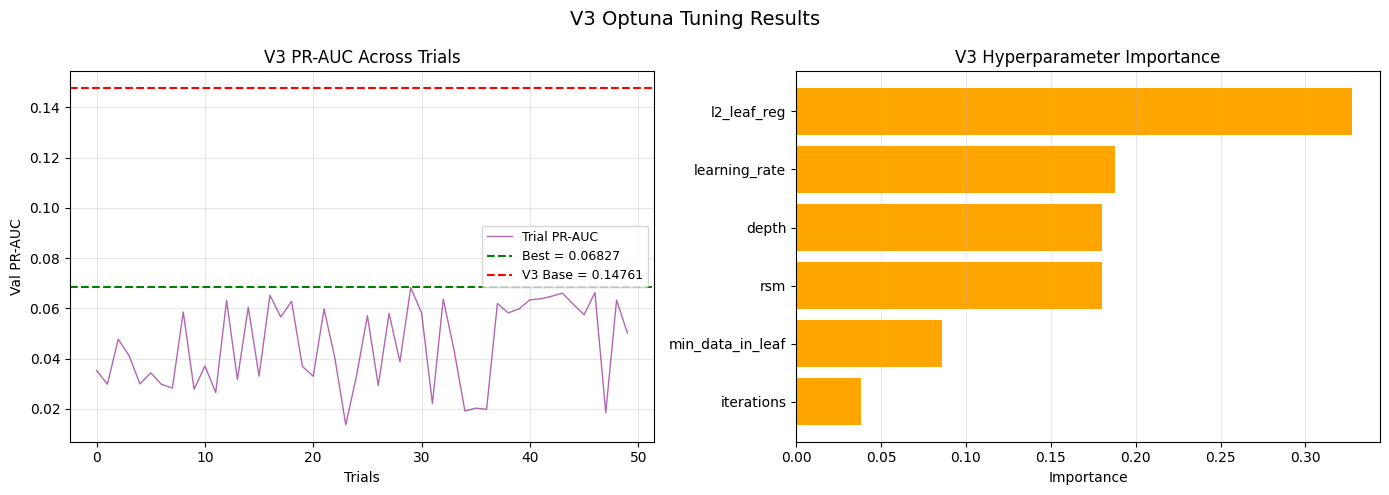

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("V3 Optuna Tuning Results", fontsize=14)

# PR-AUC Progression
ax = axes[0]
trial_values = [t.value for t in study.trials if t.value is not None]

ax.plot(trial_values, color="purple", linewidth=1, alpha=0.6, label="Trial PR-AUC")
ax.axhline(
    best_pr_auc, color="green", linestyle="--",
    linewidth=1.5, label=f"Best = {best_pr_auc:.5f}"
)
ax.axhline(
    v3_base_val_metrics["pr_auc"], color="red", linestyle="--",
    linewidth=1.5, label=f"V3 Base = {v3_base_val_metrics["pr_auc"]:.5f}"
)

ax.set_title("V3 PR-AUC Across Trials")
ax.set_xlabel("Trials")
ax.set_ylabel("Val PR-AUC")
ax.legend(fontsize=9)
ax.grid(alpha=0.3)

# Parameter Importance
ax = axes[1]
importance = optuna.importance.get_param_importances(study)
param_list = list(importance.keys())[:8]
value_list = [importance[p] for p in param_list]

ax.barh(param_list[::-1], value_list[::-1], color="orange")
ax.set_title("V3 Hyperparameter Importance")
ax.set_xlabel("Importance")
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

#### ***PR-AUC declined from 0.14761 (baseline) to 0.06927 (best Optuna trial) : Optuna made V3 CatBoost worse***

In [49]:
print("Since Optuna is worse that baseline, moving ahead with Baseline V3 CatBoost :-")
print(f"\nV3 scale_pos_weight : {SCALE_POS_WEIGHT}")
print(f"V3 Learning Rate : {baseline_parameters['learning_rate']:.6f}")
print(f"V3 rsm : {catb_v3_base.get_all_params()['rsm']:.6f}")
print(f"V3 iterations max : {baseline_parameters['iterations']}")

trees_used = baseline_parameters["iterations"]
print(f"Trees Used : {trees_used}")

Since Optuna is worse that baseline, moving ahead with Baseline V3 CatBoost :-

V3 scale_pos_weight : 807.2838
V3 Learning Rate : 0.050000
V3 rsm : 1.000000
V3 iterations max : 1000
Trees Used : 1000


### CatBoost Feature Importance

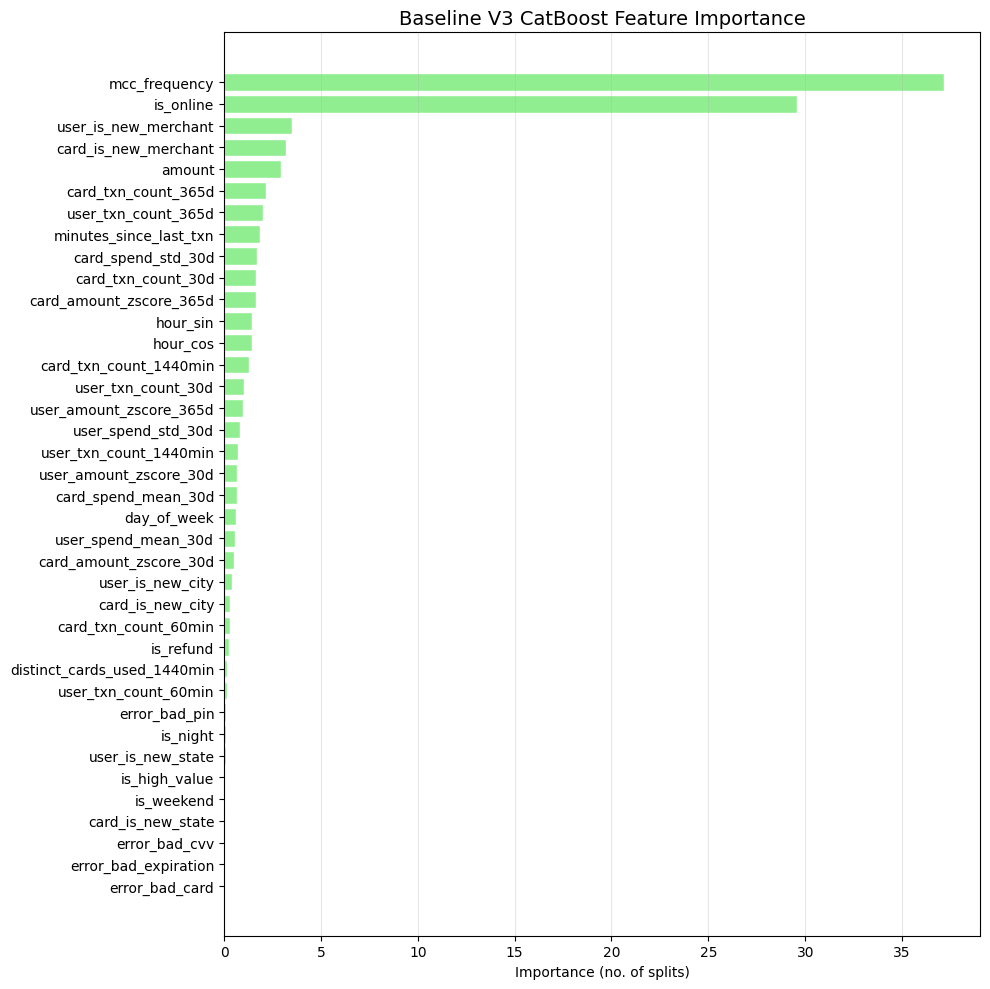


Top 10 features :
mcc_frequency                  : 37.16634389679968
is_online                      : 29.56877646726254
user_is_new_merchant           : 3.5073616960728704
card_is_new_merchant           : 3.1962530806085696
amount                         : 2.9258006243997197
card_txn_count_365d            : 2.1593499092292783
user_txn_count_365d            : 2.0049904279257325
minutes_since_last_txn         : 1.8303608385882466
card_spend_std_30d             : 1.6925875385796099
card_txn_count_30d             : 1.6398907815977797

Zero Importance Features (0) : 


In [50]:
importance = sorted(
    zip(FEATURE_COLS, catb_v3_base.feature_importances_),
    key=lambda x : x[1],
    reverse=True
)
 
features = [f for f, _ in importance]
imp_values = [v for _, v in importance]

fig, ax = plt.subplots(figsize=(10, 10))

colors = ["lightgreen" if v > 0 else "red" for v in imp_values]
ax.barh(features[::-1], imp_values[::-1], color=colors[::-1], edgecolor="white")

ax.set_title("Baseline V3 CatBoost Feature Importance", fontsize=14)
ax.set_xlabel("Importance (no. of splits)")
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

print(f"\nTop 10 features :")
for f, v in importance[:10]:
    print(f"{f:<30} : {v:,}")

zero_imp = [f for f, v in importance if v == 0]
print(f"\nZero Importance Features ({len(zero_imp)}) : ")
for f in zero_imp:
    print(f"{f}")

In [ ]:
# Clearing space
del x_train_tune, y_train_tune, x_val_tune, y_val_tune
gc.collect()

## V3 Isolation Forest

### Training & Scores

In [21]:
from sklearn.ensemble import IsolationForest

ISO_CONTAMINATION = config["model"]["isolation_forest"]["contamination"]
ISO_N_ESTIMATORS = config["model"]["isolation_forest"]["n_estimators"]

print("Training Isolation Forest on sample training data (V3) ...")
print(f"Training : {len(x_train_final):,} Rows")
 
iso_forest_v3 = IsolationForest(
    contamination = ISO_CONTAMINATION,
    n_estimators = ISO_N_ESTIMATORS,
    random_state = RANDOM_STATE,
    n_jobs = -1
)

iso_forest_v3.fit(x_train_final)
print("\nV3 Isolation Forest Trained")

# Raw Anomaly Scores on full Val
# High score- more anomalous, Low score- more normal
raw_iso_val = -iso_forest_v3.decision_function(x_val)  # Inverting

raw_iso_min = raw_iso_val.min()
raw_iso_max = raw_iso_val.max()

print("\nRaw Anomaly Score on Val :")
print(f"Mean : {raw_iso_val.mean():.5f}")
print(f"Std : {raw_iso_val.std():.5f}")
print(f"Min : {raw_iso_min:.5f}")
print(f"Max : {raw_iso_max:.5f}")

# Normalizing raw scores
norm_iso_val = (raw_iso_val - raw_iso_min) / (raw_iso_max - raw_iso_min)

print("\nNormalized Anomaly Score on Val :")
print(f"Mean : {norm_iso_val.mean():.5f}")
print(f"Std : {norm_iso_val.std():.5f}")
print(f"Min : {norm_iso_val.min():.5f}")
print(f"Max : {norm_iso_val.max():.5f}")

Training Isolation Forest on sample training data (V3) ...
Training : 5,000,000 Rows

V3 Isolation Forest Trained

Raw Anomaly Score on Val :
Mean : -0.16319
Std : 0.04748
Min : -0.23277
Max : 0.14369

Normalized Anomaly Score on Val :
Mean : 0.18483
Std : 0.12611
Min : 0.00000
Max : 1.00000


### Isolation Forest Fraud Signal

In [22]:
iso_fraud_mean = norm_iso_val[y_val == 1].mean()
iso_non_fraud_mean = norm_iso_val[y_val == 0].mean()
iso_pr_auc = average_precision_score(y_val, norm_iso_val)

print("V3 Isolation Forest on Val :")
print(f"Fraud Mean Anomaly Score : {iso_fraud_mean:.5f}")
print(f"Non-Fraud Mean Anomaly Score : {iso_non_fraud_mean:.5f}")
print(f"Isolation Forest PR-AUC : {iso_pr_auc:.5f}")

V3 Isolation Forest on Val :
Fraud Mean Anomaly Score : 0.30957
Non-Fraud Mean Anomaly Score : 0.18465
Isolation Forest PR-AUC : 0.00477


# V3 Hybrid Weights & Threshold

## Hybrid Weights

In [52]:
print("Calculating V3 Hybrid Weights ...")
print(f"V3 Isolation Forest PR-AUC : {iso_pr_auc:.5f}")
print(f"V3 Baseline CatBoost PR-AUC : {v3_base_val_metrics['pr_auc']:.5f}\n")

weights = []
for w1 in [0.5, 0.6, 0.7, 0.8, 0.9, 1.0]:
    w2 = round(1 - w1, 1)
    hybrid_scores = w1 * v3_base_val_prob + w2 * norm_iso_val
    pr_auc = average_precision_score(y_val, hybrid_scores)
    roc_auc = roc_auc_score(y_val, hybrid_scores)

    weights.append({
        "catb_weight" : w1,
        "iso_weight" : w2,
        "pr_auc" : round(pr_auc, 5),
        "roc_auc" : round(roc_auc, 5)
    })

weight_df = pd.DataFrame(weights).sort_values("pr_auc", ascending=False)
print(weight_df.to_string(index=False))

best_weights = weight_df.iloc[0]
BEST_V3_CATB_WEIGHT = float(best_weights["catb_weight"])
BEST_V3_ISO_WEIGHT = float(best_weights["iso_weight"])

print("\nBest V3 Weights :-")
print(f"CatBoost V3 Weight - {BEST_V3_CATB_WEIGHT}")
print(f"Isolation Forest V3 Weight - {BEST_V3_ISO_WEIGHT}")

print(f"\nV3 CatBoost PR-AUC : {v3_base_val_metrics['pr_auc']:.5f}")
print(f"Hybrid V3 PR-AUC : {best_weights['pr_auc']:.5f}")
print(f"Delta : {best_weights['pr_auc'] - v3_base_val_metrics['pr_auc']:+.5f}")

if BEST_V3_ISO_WEIGHT == 0.00:
    print("\nV3 Isolation Forest adds no value, V3 Baseline CatBoost alone is better than V3 hybrid")

Calculating V3 Hybrid Weights ...
V3 Isolation Forest PR-AUC : 0.00477
V3 Baseline CatBoost PR-AUC : 0.14761

 catb_weight  iso_weight  pr_auc  roc_auc
         1.0         0.0 0.14761  0.94045
         0.9         0.1 0.10774  0.93064
         0.8         0.2 0.09004  0.91995
         0.7         0.3 0.07745  0.90899
         0.6         0.4 0.06658  0.89718
         0.5         0.5 0.05650  0.88376

Best V3 Weights :-
CatBoost V3 Weight - 1.0
Isolation Forest V3 Weight - 0.0

V3 CatBoost PR-AUC : 0.14761
Hybrid V3 PR-AUC : 0.14761
Delta : +0.00000

V3 Isolation Forest adds no value, V3 Baseline CatBoost alone is better than V3 hybrid


### Saving to Config

In [53]:
config["model"]["v3_hybrid"]["catb_weight"] = BEST_V3_CATB_WEIGHT
config["model"]["v3_hybrid"]["iso_weight"] = BEST_V3_ISO_WEIGHT

with open(CONFIG_PATH, "w") as f:
    yaml.safe_dump(config, f, sort_keys=False)

print("V3 Weights saved to config.yaml")

V3 Weights saved to config.yaml


## Threshold Optimization

In [54]:
# Using only CatBoost Model
RECALL_FLOOR = config["model"]["recall_floor"]
FP_COST = config["model"]["fp_cost"]

fraud_prob_val = v3_base_val_prob[y_val == 1]
non_fraud_prob_val = v3_base_val_prob[y_val == 0]

print("Optimising Threshold on V3 Val :-")
print("False Negative Cost : Actual Transaction Amount")
print(f"False Positive Cost : ${FP_COST:.2f} per False Alarms")
print(f"Recall Floor (minimun) : {RECALL_FLOOR}")

print(f"\nFruad transactions in Val : {len(fraud_amount_val):,}")
print(f"Average Fraud Amount : ${fraud_amount_val.mean():,.2f}")
print(f"Total Fraud Amount : ${fraud_amount_val.sum():,.2f}")

thresholds = np.arange(0.1, 0.99, 0.01).round(2)

# Vectorized calculation
# Shapes = (n_threshold, n_fraud_val), (n_threshold, n_non_fraud_val)
fraud_caught = fraud_prob_val[None, :] >= thresholds[:, None]
fraud_missed = ~fraud_caught

fn_loss = (fraud_missed * fraud_amount_val[None, :]).sum(axis=1)

fp_counts = (non_fraud_prob_val[None, :] >= thresholds[:, None]).sum(axis=1)
fp_loss = fp_counts * FP_COST

total_loss = fn_loss + fp_loss

threshold_result = []
for i, threshold in enumerate(thresholds):
    preds = (v3_base_val_prob >= threshold).astype(int)

    tn = int(((preds == 0) & (y_val == 0)).sum())
    fn = int(fraud_missed[i].sum())
    fp = int(fp_counts[i])
    fpr = fp / (fp + tn) if (fp + tn) > 0 else 0.00

    recall = float(recall_score(y_val, preds, zero_division=0))
    precision = float(precision_score(y_val, preds, zero_division=0))
    f1 = float(f1_score(y_val, preds, zero_division=0))

    threshold_result.append({
        "threshold" : threshold,
        "total_loss" : round(total_loss[i], 2),
        "fn_loss" : round(fn_loss[i], 2),
        "fp_loss" : round(fp_loss[i], 2),
        "fn_count" : fn,
        "fp_count" : fp,
        "recall" : round(recall, 5),
        "precision" : round(precision, 5),
        "f1" : round(f1, 5),
        "fpr" : round(fpr, 5),

    })

result_df = pd.DataFrame(threshold_result)
threshold_df = result_df[result_df["recall"] >= RECALL_FLOOR]  # balancing with fpr

if len(threshold_df) == 0:
    print(f"\nNo threshold with recall >= {RECALL_FLOOR} | Relaxing recall_floor for V3")
    
    best_row = result_df.loc[result_df["total_loss"].idxmin()]
    BEST_V3_THRESHOLD = float(best_row["threshold"])
    
    print(f"\nBest V3 Threshold (relaxed) : {BEST_V3_THRESHOLD}")
    print(f"Recall : {best_row['recall']:.5f}")
    
else:
    best_row = threshold_df.loc[threshold_df["total_loss"].idxmin()]
    BEST_V3_THRESHOLD = float(best_row["threshold"])
    
    print(f"\nBest V3 Threshold : {BEST_V3_THRESHOLD}")
    print(f"Recall : {best_row['recall']:.5f}")

print(f"\nTotal Loss : ${best_row['total_loss']:,.2f}")
print(f"FN Loss : ${best_row['fn_loss']:,.2f} ({best_row['fn_count']:,.0f} frauds missed)")
print(f"FP Loss : ${best_row['fp_loss']:,.2f} ({best_row['fp_count']:,.0f} false alarms raised)")
print(f"\nPrecision : {best_row['precision']:.5f}")
print(f"F1 : {best_row['f1']:.5f}")
print(f"PR-AUC : {average_precision_score(y_val, v3_base_val_prob):.5f}")
print(f"FPR : {best_row['fpr']:.5f}")

Optimising Threshold on V3 Val :-
False Negative Cost : Actual Transaction Amount
False Positive Cost : $2.00 per False Alarms
Recall Floor (minimun) : 0.75

Fruad transactions in Val : 2,491
Average Fraud Amount : $79.40
Total Fraud Amount : $197,795.45

Best V3 Threshold : 0.26
Recall : 0.75231

Total Loss : $206,779.47
FN Loss : $24,865.47 (617 frauds missed)
FP Loss : $181,914.00 (90,957 false alarms raised)

Precision : 0.02019
F1 : 0.03932
PR-AUC : 0.14761
FPR : 0.05291


### Visualizing

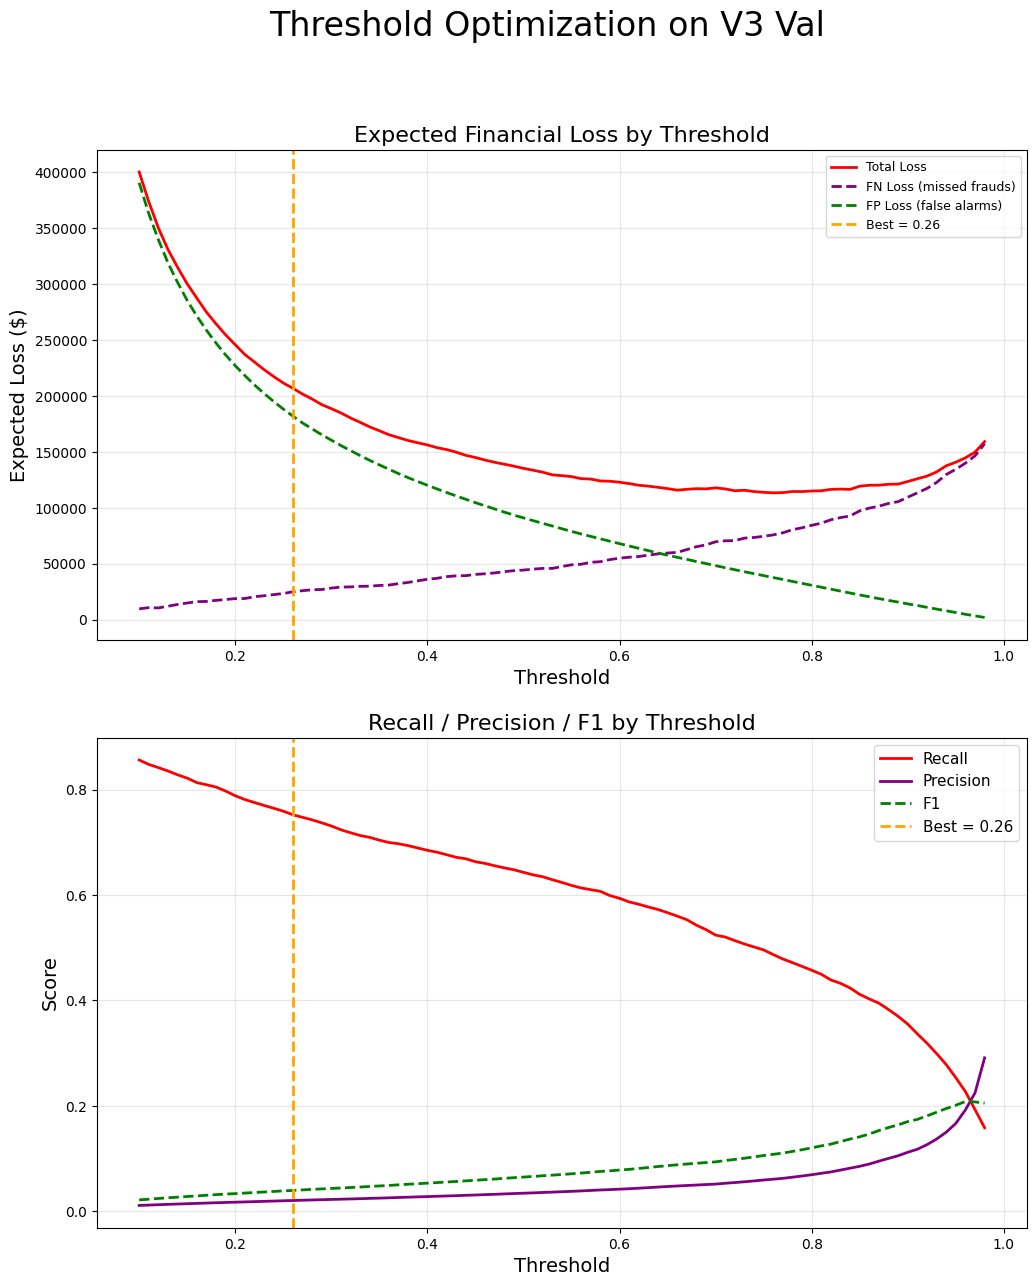

In [55]:
fig, axes = plt.subplots(2, 1, figsize=(12, 14))
fig.suptitle("Threshold Optimization on V3 Val", fontsize=24)

ax = axes[0]
ax.plot(result_df["threshold"], result_df["total_loss"], color="red",
        linewidth=2, label="Total Loss")
ax.plot(result_df["threshold"], result_df["fn_loss"], color="purple",
        linewidth=2, linestyle="--", label="FN Loss (missed frauds)")
ax.plot(result_df["threshold"], result_df["fp_loss"], color="green",
        linewidth=2, linestyle="--", label="FP Loss (false alarms)")
ax.axvline(BEST_V3_THRESHOLD, color="orange", linewidth=2, 
           linestyle="--", label=f"Best = {BEST_V3_THRESHOLD}")

ax.set_title("Expected Financial Loss by Threshold", fontsize=16)
ax.set_xlabel("Threshold", fontsize=14)
ax.set_ylabel("Expected Loss ($)", fontsize=14)
ax.legend(fontsize=9)
ax.grid(alpha=0.3)

ax = axes[1]
ax.plot(result_df["threshold"], result_df["recall"], color="red",
        linewidth=2, label="Recall")
ax.plot(result_df["threshold"], result_df["precision"], color="purple",
        linewidth=2, label="Precision")
ax.plot(result_df["threshold"], result_df["f1"], color="green",
        linewidth=2, linestyle="--", label="F1")
ax.axvline(BEST_V3_THRESHOLD, color="orange", linewidth=2, 
           linestyle="--", label=f"Best = {BEST_V3_THRESHOLD}")

ax.set_title("Recall / Precision / F1 by Threshold", fontsize=16)
ax.set_xlabel("Threshold", fontsize=14)
ax.set_ylabel("Score", fontsize=14)
ax.legend(fontsize=11)
ax.grid(alpha=0.3)

plt.show()

### Saving to Config

In [56]:
print("V3 Val score distribution :")
for pct in [90, 95, 97, 99, 99.5, 99.9]:
    val = np.percentile(v3_base_val_prob, pct)
    print(f"{pct}th percentile : {val:.5f}")

V3 Val score distribution :
90th percentile : 0.11975
95th percentile : 0.28381
97th percentile : 0.46592
99th percentile : 0.79165
99.5th percentile : 0.89163
99.9th percentile : 0.97517


In [57]:
config["model"]["v3_threshold"] = BEST_V3_THRESHOLD

config["risk"]["v3_thresholds"]["low"] = round(float(np.percentile(v3_base_val_prob, 90)), 3)
config["risk"]["v3_thresholds"]["medium"] = round(float(np.percentile(v3_base_val_prob, 95)), 3)
config["risk"]["v3_thresholds"]["high"] = round(float(np.percentile(v3_base_val_prob, 97)), 3)
config["risk"]["v3_thresholds"]["critical"] = BEST_V3_THRESHOLD

with open(CONFIG_PATH, "w") as f:
    yaml.safe_dump(config, f, sort_keys=False)

print("Saved to config.yaml")

Saved to config.yaml


# Final Evaluation on V3 Test

In [58]:
catb_v3_val_prob, catb_v3_val_metrics = evaluate_model(
    catb_v3_base, x_val, y_val,
    threshold=BEST_V3_THRESHOLD,
    split_name="V3 Final Val"
)

catb_v3_test_prob, catb_v3_test_metrics = evaluate_model(
    catb_v3_base, x_test, y_test,
    threshold=BEST_V3_THRESHOLD,
    split_name="V3 Final Test"
)

print("\n\nFinal V3 Evaluation (full Test) :")
print(f"Threshold = {BEST_V3_THRESHOLD}")

print(f"\n{'Metric':<18} {'V3 Test':>12} {'V3 Val':>12} {'Delta':>12}")
for metric in [
    "pr_auc", "roc_auc", "f1", "recall", "precision", "fpr", "recall_at_0.1_fpr",
    "recall_at_1_fpr", "precision_top_1k", "precision_top_5k", "precision_top_10k"
]:
    v3_val_metric = catb_v3_val_metrics.get(metric, 0.0)
    v3_test_metric = catb_v3_test_metrics[metric]
    delta = v3_test_metric - v3_val_metric
    print(f"{metric:<18} {v3_test_metric:>12.5f} {v3_val_metric:>12.5f} {delta:>+12.5f}")

05-08-2026 01:25:28 | INFO | V3 Final Val Evaluation (threshold = 0.26):
05-08-2026 01:25:28 | INFO | pr_auc             : 0.14761
05-08-2026 01:25:28 | INFO | roc_auc            : 0.94045
05-08-2026 01:25:28 | INFO | f1                 : 0.03932
05-08-2026 01:25:28 | INFO | recall             : 0.75231
05-08-2026 01:25:28 | INFO | precision          : 0.02019
05-08-2026 01:25:28 | INFO | fpr                : 0.05291
05-08-2026 01:25:28 | INFO | recall_at_0.1_fpr  : 0.19671
05-08-2026 01:25:28 | INFO | recall_at_1_fpr    : 0.47330
05-08-2026 01:25:28 | INFO | precision_top_1k   : 0.33300
05-08-2026 01:25:28 | INFO | precision_top_5k   : 0.14340
05-08-2026 01:25:28 | INFO | precision_top_10k  : 0.09710
05-08-2026 01:25:35 | INFO | V3 Final Test Evaluation (threshold = 0.26):
05-08-2026 01:25:35 | INFO | pr_auc             : 0.06596
05-08-2026 01:25:35 | INFO | roc_auc            : 0.93484
05-08-2026 01:25:35 | INFO | f1                 : 0.02690
05-08-2026 01:25:35 | INFO | recall      



Final V3 Evaluation (full Test) :
Threshold = 0.26

Metric                  V3 Test       V3 Val        Delta
pr_auc                  0.06596      0.14761     -0.08165
roc_auc                 0.93484      0.94045     -0.00561
f1                      0.02690      0.03932     -0.01242
recall                  0.72592      0.75231     -0.02639
precision               0.01370      0.02019     -0.00649
fpr                     0.05298      0.05291     +0.00007
recall_at_0.1_fpr       0.14327      0.19671     -0.05344
recall_at_1_fpr         0.42932      0.47330     -0.04398
precision_top_1k        0.18000      0.33300     -0.15300
precision_top_5k        0.08960      0.14340     -0.05380
precision_top_10k       0.06510      0.09710     -0.03200


#### Test metrics are lower that Val metrics.
##### This is due to temporal fraud distribution and behaviour shift-
##### 1. Val (2018)  : 0.145% fraud rate -> used for threshold tuning
##### 2. Test (2019 - 2020) : 0.101% fraud rate -> 30% lower fraud & changed fraud patterns

#### There is no overfitting, but model metrics confirm temporal drift and need for future retraining.
##### ROC-AUC (0.94045 -> 0.93484) and FPR (0.05291 -> 0.05298) remain stable : model ranks fraud and non-fraud well.
##### PR-AUC (0.14761 -> 0.06596) and Precision @ Top 1K (0.33300 -> 0.18000) drop : Model is not confident with fraud scores in post-chip era.

## Financial Impact

In [59]:
test_fraud_prob = catb_v3_test_prob[y_test == 1]
test_non_fraud_prob = catb_v3_test_prob[y_test == 0]

test_fraud_caught = int((test_fraud_prob >= BEST_V3_THRESHOLD).sum())
test_fraud_missed = int((test_fraud_prob < BEST_V3_THRESHOLD).sum())
test_false_alarms = int((test_non_fraud_prob >= BEST_V3_THRESHOLD).sum())

test_fn_loss = float(test_fraud_amount[test_fraud_prob < BEST_V3_THRESHOLD].sum())
test_fp_loss = test_false_alarms * FP_COST
test_total_loss = test_fn_loss + test_fp_loss

print("Financial Impact on V3 Test data :")
print(f"Fraud Caught : {test_fraud_caught:,} / {len(test_fraud_amount):,} ({test_fraud_caught / len(test_fraud_amount) * 100:.2f}%)")
print(f"Fraud Missed : {test_fraud_missed:,}")
print(f"False Alarms : {test_false_alarms:,}")

print(f"\nFN Loss : ${test_fn_loss:,.2f}")
print(f"FP Loss : ${test_fp_loss:,.2f}")
print(f"Total Loss : ${test_total_loss:,.2f}")

Financial Impact on V3 Test data :
Fraud Caught : 1,515 / 2,087 (72.59%)
Fraud Missed : 572
False Alarms : 109,042

FN Loss : $26,185.88
FP Loss : $218,084.00
Total Loss : $244,269.88


## Visualization

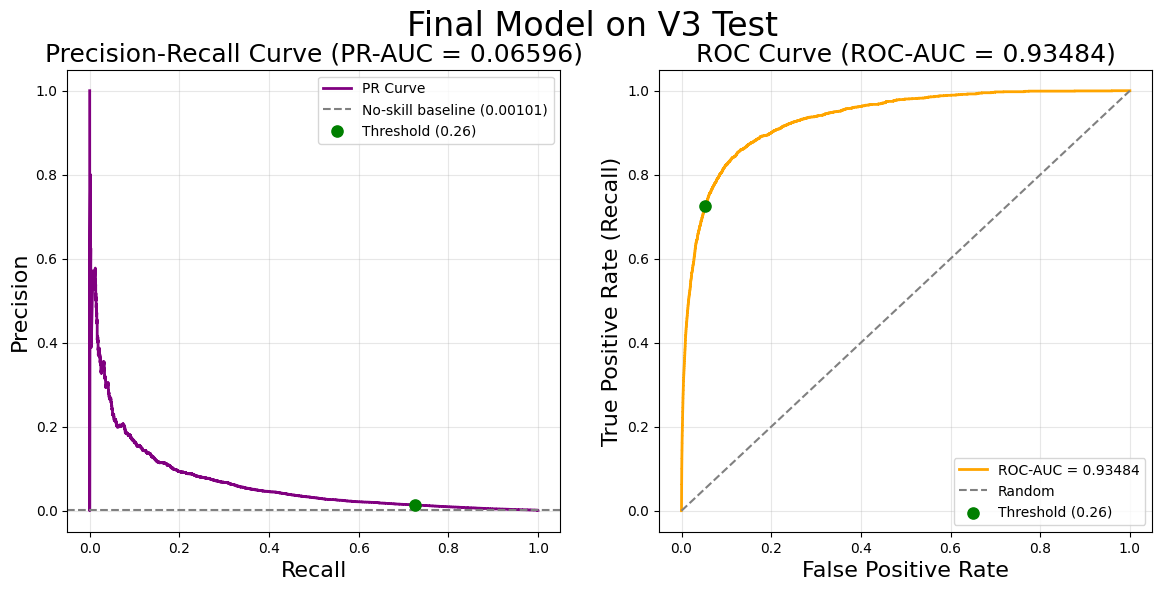

In [60]:
from sklearn.metrics import precision_recall_curve

pr_arr, rec_arr, _ = precision_recall_curve(y_test, catb_v3_test_prob)
fpr_arr, tpr_arr, _ = roc_curve(y_test, catb_v3_test_prob)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle("Final Model on V3 Test", fontsize=24)

ax = axes[0]
ax.plot(rec_arr, pr_arr, color="purple", linewidth=2, label="PR Curve")
ax.axhline(y_test.mean(), color="gray", linestyle="--", 
        label=f"No-skill baseline ({y_test.mean():.5f})")
ax.scatter(catb_v3_test_metrics["recall"], catb_v3_test_metrics["precision"],
           color="green", s=65, zorder=5, label=f"Threshold ({BEST_V3_THRESHOLD})")

ax.set_title(
    f"Precision-Recall Curve (PR-AUC = {catb_v3_test_metrics['pr_auc']:.5f})",
    fontsize=18
)
ax.set_xlabel("Recall", fontsize=16)
ax.set_ylabel("Precision", fontsize=16)
ax.legend(fontsize=10)
ax.grid(alpha=0.3)

ax = axes[1]
ax.plot(fpr_arr, tpr_arr, color="orange", linewidth=2, 
        label=f"ROC-AUC = {catb_v3_test_metrics["roc_auc"]:.5f}")
ax.plot([0, 1], [0, 1], color="gray", linestyle="--", label="Random")
ax.scatter(catb_v3_test_metrics['fpr'], catb_v3_test_metrics['recall'], 
            color="green", s=65, zorder=5, label=f"Threshold ({BEST_V3_THRESHOLD})")

ax.set_title(
    f"ROC Curve (ROC-AUC = {catb_v3_test_metrics['roc_auc']:.5f})",
    fontsize=18
)
ax.set_xlabel("False Positive Rate", fontsize=16)
ax.set_ylabel("True Positive Rate (Recall)", fontsize=16)
ax.legend(fontsize=10)
ax.grid(alpha=0.3)

plt.show()

#### Out of 10,000 alerts-
##### Random Classification : 10 actual frauds, 9990 false alarms (0.00101)
##### Model Classification : 137 actual frauds, 9863 false alarms (0.01370)

#### Model is 13.6x better at identifying frauds.

## Saving Artifacts

In [63]:
catb_path = PROJECT_ROOT / config["artifacts"]["catb_v3_path"]
iso_path = PROJECT_ROOT / config["artifacts"]["iso_v3_path"]

joblib.dump(catb_v3, catb_path)
joblib.dump(iso_forest_v3, iso_path)

print("Saved as model artifacts")

Saved as model artifacts


# Summary

In [67]:
print("V3 Data :")
print(f"Train ({V2_TRAIN_START} to {V2_TRAIN_END}) : {len(x_train):,} Rows")
print(f"Val ({V2_VAL_START} to {V2_VAL_END}) : {len(x_val):,} Rows")
print(f"Test ({V2_TEST_START} to {V2_TEST_END}) : {len(x_test):,} Rows")
print(f"Features : {len(FEATURE_COLS)}")

print("\nV3 Model :")
print("Algorithm : CatBoost")
print(f"Trees Used : {trees_used}")
print(f"scale_pos_weight : {SCALE_POS_WEIGHT}")
print(f"Hybrid weight : {config["model"]["v3_hybrid"]["catb_weight"]}\n")
for key, value in config["model"]["catboost"]["baseline"].items():
    print(f"{key:<18} : {value}")

print("\nIsolation Forest :")
print(f"Hybrid weight : {config["model"]["v3_hybrid"]["iso_weight"]}")
print("Most optimal V3 model is CatBoost only")

print(f"\nThreshold : {BEST_V3_THRESHOLD}")
print(f"FP Cost : ${FP_COST:.2f}")
print("FN Cost : actual transaction amount")

delta = catb_v3_val_metrics['recall'] - RECALL_FLOOR
print(f"\nRecall Floor : {RECALL_FLOOR}")
print(f"Recall achieved : {catb_v3_val_metrics['recall']:.6f} | delta : {delta:+.6f}")
if delta < 0.0:
    print(f"Recall floor not achievable, threshold optimized to minimize expected financial loss")

print(f"\nV3 retrained as a candidate model for promotion")

print(f"\nVal Metrics (threshold={BEST_V3_THRESHOLD})")
for key, value in catb_v3_val_metrics.items():
    print(f"{key:<18} : {value:.5f}")

print(f"\nTest Metrics (threshold={BEST_V3_THRESHOLD})")
for key, value in catb_v3_test_metrics.items():
    print(f"{key:<18} : {value:.5f}")

print("\nFinancial Impact on V3 Test :")
print(f"Fraud Caught : {test_fraud_caught:,} / {len(test_fraud_amount):,} ({test_fraud_caught / len(test_fraud_amount) * 100:.2f}%)")
print(f"False Alarms : {test_false_alarms:,}")
print(f"FN Loss : ${test_fn_loss:,.2f}")
print(f"FP Loss : ${test_fp_loss:,.2f}")
print(f"Total Loss : ${test_total_loss:,.2f}")

print("\nArtifacts :")
print(f"{catb_path.name}")
print(f"{iso_path.name}")

V3 Data :
Train (1991 to 2017) : 20,604,650 Rows
Val (2018 to 2018) : 1,721,605 Rows
Test (2019 to 2020) : 2,060,423 Rows
Features : 38

V3 Model :
Algorithm : CatBoost
Trees Used : 1000
scale_pos_weight : 807.2838
Hybrid weight : 1.0

loss_function      : Logloss
eval_metric        : AUC
learning_rate      : 0.05
depth              : 6
iterations         : 1000
l2_leaf_reg        : 3.0
bagging_temperature : 0.5
min_data_in_leaf   : 50
rsm                : 1

Isolation Forest :
Hybrid weight : 0.0
Most optimal V3 model is CatBoost only

Threshold : 0.26
FP Cost : $2.00
FN Cost : actual transaction amount

Recall Floor : 0.75
Recall achieved : 0.752310 | delta : +0.002310

V3 retrained as a candidate model for promotion

Val Metrics (threshold=0.26)
pr_auc             : 0.14761
roc_auc            : 0.94045
f1                 : 0.03932
recall             : 0.75231
precision          : 0.02019
fpr                : 0.05291
recall_at_0.1_fpr  : 0.19671
recall_at_1_fpr    : 0.47330
precision